##  Binarización de la imagen
Para binarizar la imagen se utilizo un umbral de 150, pero encontramos el siguiente problema
![texto del enlace](https://drive.google.com/uc?id=1Zc85CvRhyWy3iwmnnCmYnNKqfFZYXVdl)

Como se puede observar en la imagen después de la fia 650 los granos de arroz no se lográn reconocer bien, es por eso que se decidio aplicar dos umbrales diferentes, uno desde el inicio de la imagen hasta la fila 500, en donde se aplico un umbral de 150, lo recomendado en la rubrica y de la fila 500 hasta el final de la imagen se aplico un umbral de 130, con este cambio se lograron observar todos los granos de arro con una mejor calidad.

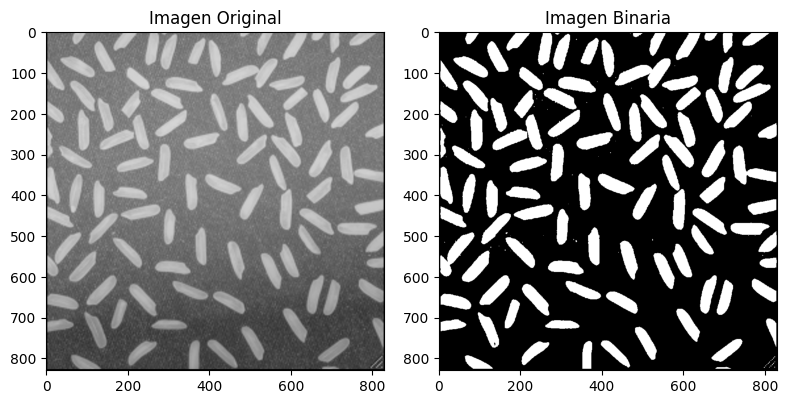

In [ ]:
#=== Binarización de la imagen ===
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread("img/rice.png")

#Debido a que la imagen no tiene la misma iluminación en todo los granos, se decidio aplicar dos umbrales en la imagen
#Para que asi, se puedan obtener todos los granos en la imagen binaria
imgBinaria = img.copy()


_, imgBinaria[0:500:1] = cv2.threshold(imgBinaria[0:500], 150, 255, cv2.THRESH_BINARY)
_, imgBinaria[500::1] = cv2.threshold(imgBinaria[500:], 130, 255, cv2.THRESH_BINARY)

#Creamos una figura donde colocar ambas imagenes, la original y la binaria
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Imagen Original")

plt.subplot(1, 2, 2)
plt.imshow(imgBinaria, cmap="gray")
plt.title("Imagen Binaria")

plt.tight_layout()
plt.show()


## Etiquetar los componentes y obtener las regiones por grano

Para poder etiquetar los componentes de la imagen se utilizo la funcion **cv2.connectedComponentsWithStats**, esta función análiza los puntos blancos de la imagen binaria y nos entrega información importante:
1. **Número total de etiquetas:** La cantidad de objetos encontrados en la imagen, incluyendo el fondo.

2. **Mapa de la etiquetas:** Matriz del mismo tamaño que la original donde cada pixel tiene el número de la etiqueta a la pertenece
![texto del enlace](https://drive.google.com/uc?id=16bVOBVbNNGXSnZWbX6Ben0tmyoyUUD75)

3. **Estadísticas:** Una matriz con información greometrica importante por cada etiqueta:

    a. **CC_STAT_LEFT:** La coordenada X de la esquina superior izquierda del cuadro delimitador (bounding box).

    b. **CC_STAT_TOP:** La coordenada Y de la esquina superior izquierda del cuadro delimitador.

    c. **CC_STAT_WIDTH:** Ancho del cuadro delimitador.

    d. **CC_STAT_HEIGHT:** Alto del cuadro delimitador.

    e. **CC_STAT_AREA:** Numero de pixeles que forman el aŕea.

    pd: Cuando se habla de cuadro delimitador, nos referimos al rectángulo más pequeño posible que puede tener dentro al objeto

4. **Centroides:** Las coordenadas del centro de masa del objeto


Con lo anterior explicado podemos limpiar la imagen, borrando el ruido, esto lo logramos viendo la media de las etiquetas, a partir de la media hacemos un rango de los datos y los valores que no cumplan son ruido.


Promedio de las áreas: 1179.03125
97
La cantidad de etiquetas son: 161


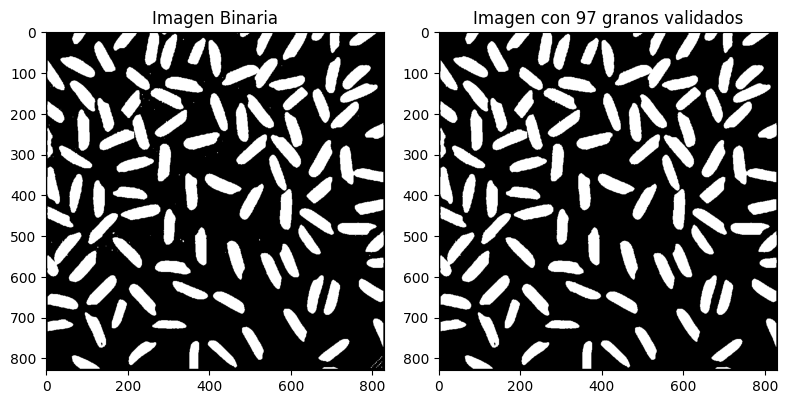

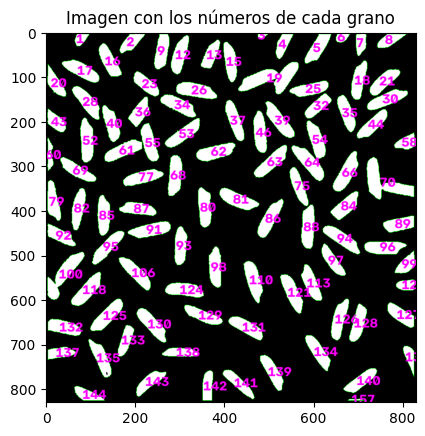

In [112]:
#=== Etiquetar componentes, obtener región por grano y perimetro===
imgBinariaGris = cv2.cvtColor(imgBinaria, cv2.COLOR_BGR2GRAY)
output = cv2.connectedComponentsWithStats(imgBinariaGris, connectivity=8, ltype=cv2.CV_32S)

"""
print(f"La cantidad de etiquetas son: {output[0]}")
print("============================================")
plt.imshow(output[1], cmap="gray")
plt.title("Mapa de las etiquetas")
plt.show()
print("============================================")
print(f"La matriz de estadisticas es: {output[2]}")
print("============================================")
print(f"La matriz de los centroides es: {output[3]}")
print("============================================")
"""
estadisticas = output[2]
media = np.mean(estadisticas[1:, cv2.CC_STAT_AREA])
#print(estadisticas[1:, cv2.CC_STAT_AREA])
print(f"Promedio de las áreas: {media}")
print

limite = 1100
indiceEtiquetas= []

#Logica para obtener los indices de los granos y no ruido o granos en los bordes
for i, valor in enumerate(estadisticas[1:, cv2.CC_STAT_AREA], start= 1):
  #print(f"Grano con área de: {valor}")
  if valor > media-limite:
    indiceEtiquetas.append(i)
    #print("== ACEPTADO ==")
  #else:
    #print("RECHAZADO")



print(len(indiceEtiquetas))
print(f"La cantidad de etiquetas son: {output[0]}")



# Máscara: True donde el píxel pertenece a una etiqueta válida
mascaraValida = np.isin(output[1],indiceEtiquetas )

# Imagen a mostrar: 255 donde es válido, 0 donde no
imgValida = (mascaraValida * 255).astype(np.uint8)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(imgBinariaGris, cmap="gray")
plt.title("Imagen Binaria")

plt.subplot(1, 2, 2)
plt.imshow(imgValida, cmap = "gray")
plt.title(f"Imagen con {len(indiceEtiquetas)} granos validados")

plt.tight_layout()
plt.show()

#=== Calculo del perímetro ===
perimetros = {}

for i in indiceEtiquetas:
    mascaraGrano = (output[1] == i).astype(np.uint8) * 255
    contornos, _ = cv2.findContours(mascaraGrano, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    if contornos:
        perimetro = cv2.arcLength(contornos[0], closed=True)
        perimetros[i] = round(perimetro,2)

#Esto permite ver los valores del perimetro de cada grano
"""
for clave, valor in perimetros.items():
  print(f"El grano de índice {clave}, tiene un perimetro de {valor}")
"""
imgCopia = imgValida.copy()
imgCopia = cv2.cvtColor(imgValida, cv2.COLOR_GRAY2BGR)

# Obtencion de los contornos por medio de las máscaras
for i in indiceEtiquetas:
    # 1
    mascara = (output[1] == i).astype(np.uint8) * 255
    contornos, _ = cv2.findContours(
        mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
    )

    # Dibujamos los contornos en la imagen
    imgCopia= cv2.drawContours(imgCopia, contornos, -1, (0, 255, 0), 1)

    cx, cy = output[3][i]
    cx, cy = int(cx), int(cy)
    cv2.putText(
        imgCopia, str(i),
        (cx - 10, cy + 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (255, 0, 255),
        2,
        cv2.LINE_AA
    )
plt.imshow(imgCopia)
plt.title("Imagen con los números de cada grano")
plt.show()

___
## Color Promedio
Para calcular los colores promedios de cada grano, utilizamos la máscara de la imagen binaria y luego medimos la dirección de esa máscara pero en la imagen origina, porque de no hacerse así, se obtendria en cada grano un valor promedio de 255, porque la imagen esta binarizada y no nos sirve eso.
Por otro lado, solo calculamos el promedio de un canal ya que la imagen ya esta en escala de grises, esto nos indica que el valor en los canales es el mismo.

In [117]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


coloresMedios = {}

for i in indiceEtiquetas:
    # Obtenemos los valores del grano i, como la matriz output[1] guarda cada elemento de la imagen con un respectivo número
    # Esto nos permite solo obtener aquellos puntos correspondientes iguales a i
    mascara = (output[1] == i)

    # Extraer los píxeles del grano, respecto a la imagen original
    pixeles = img[mascara]

    #Calculamos el promedio y lo almacenamos en el diccionario
    promedio = pixeles.mean()
    coloresMedios[i] = round(promedio,2)

#Mostramos la info :D
for clave, valor in coloresMedios.items():
  print(f"El promedio de color del grano {clave}, es: {valor}")

El promedio de color del grano 1, es: 185.96
El promedio de color del grano 2, es: 193.08
El promedio de color del grano 3, es: 186.05
El promedio de color del grano 4, es: 189.78
El promedio de color del grano 5, es: 197.29
El promedio de color del grano 6, es: 193.55
El promedio de color del grano 7, es: 190.45
El promedio de color del grano 8, es: 190.05
El promedio de color del grano 9, es: 194.08
El promedio de color del grano 12, es: 191.22
El promedio de color del grano 13, es: 193.11
El promedio de color del grano 15, es: 195.31
El promedio de color del grano 16, es: 194.35
El promedio de color del grano 17, es: 190.2
El promedio de color del grano 18, es: 192.51
El promedio de color del grano 19, es: 195.99
El promedio de color del grano 20, es: 190.67
El promedio de color del grano 21, es: 197.71
El promedio de color del grano 23, es: 200.29
El promedio de color del grano 25, es: 192.64
El promedio de color del grano 26, es: 196.12
El promedio de color del grano 28, es: 191.4

___
## Gradiente promedio

Para medir qué tan bien definido está el borde de cada grano, se calculó la magnitud del gradiente de la imagen en escala de grises y se promedió en los píxeles del perímetro de cada grano.

donde se obtuve la imagen en escalas de grises más que nada para dejar en un canal la imagen, ya que esta de por si se encuentra en escala de grises.

Usamos **np.gradient()** para obtener las derivadas de cada direccion, en donde es importante aclarar que retorna la derivada en y, luego la de x

Despues para calcular la magnitud, se uso la funcion de la raiz cuadrada, esta magnitud nos indica el cambio de intensidad en ese píxel.

Despues accedimos a cada mascara por grano para obtener su direccion, de esa forma accedimos a las direcciones pero en la imagen en escala de grises y así guardamos la magnitud, para al final obtener su promedio.

In [148]:
#=== Gradiente Promedio ===

import cv2
import numpy as np
#Obtenemos la imagen en escala de grises
imgGris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gradientesPromedio = {}

#Calculamos la gradiente, np.gradiente devuelve primero la derivada de y, depués la de x
gradienteY, gradienteX = np.gradient(imgGris)

magnitud = np.sqrt(gradienteX**2 + gradienteY**2)


#Calculamos el gradiente promedio en el perimetro de cada grano
for i in indiceEtiquetas:
    # Máscara del grano i (explicado anteriormente)
    mascara = (output[1] == i).astype(np.uint8) * 255

    # Obtenemos los contornos del grano i
    contornos, _ = cv2.findContours(mascara, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    #print(contornos[0].shape)
    #Accedemos al grano i, osea al 0 y como vimos en el print, hay una dimension extra debemos eliminarla
    #El valor por ejemplo (40, 1, 2), nos indica que el primer número es la cant de pixeles del contorno
    #El segundo es un valor de relleno y el tercero la cantidad de direccion, por ende usamos el reshape y lo arreglamos
    pts = contornos[0].reshape(-1, 2)

    #Obtenemos la direccion de los contornos
    xs = pts[:, 0]      # columnas
    ys = pts[:, 1]      # filas

    # Extraemos la magnitud de cada pixel del contorno
    valores = magnitud[ys, xs]
    #Calculamos el promedio de las magnitudes
    gradienteGrano= valores.mean()

    #Guardamos en el diccionarios :D
    gradientesPromedio[i] = round(gradienteGrano,2)

for clave, valor in gradientesPromedio.items():
  print(f"Para el grano n° {clave}, se tiene el siguiente gradiente promedio: {valor}")

Para el grano n° 1, se tiene el siguiente gradiente promedio: 24.21
Para el grano n° 2, se tiene el siguiente gradiente promedio: 25.1
Para el grano n° 3, se tiene el siguiente gradiente promedio: 28.76
Para el grano n° 4, se tiene el siguiente gradiente promedio: 20.91
Para el grano n° 5, se tiene el siguiente gradiente promedio: 21.44
Para el grano n° 6, se tiene el siguiente gradiente promedio: 25.82
Para el grano n° 7, se tiene el siguiente gradiente promedio: 24.32
Para el grano n° 8, se tiene el siguiente gradiente promedio: 21.94
Para el grano n° 9, se tiene el siguiente gradiente promedio: 18.83
Para el grano n° 12, se tiene el siguiente gradiente promedio: 18.4
Para el grano n° 13, se tiene el siguiente gradiente promedio: 18.89
Para el grano n° 15, se tiene el siguiente gradiente promedio: 18.0
Para el grano n° 16, se tiene el siguiente gradiente promedio: 19.65
Para el grano n° 17, se tiene el siguiente gradiente promedio: 18.6
Para el grano n° 18, se tiene el siguiente grad

___
## Contraste

Para calcular esto es importante entender que lo que se solicita es qué tan distinto es el brillo del grano respecto a lo que lo rodea.
En donde podemos aplicar la siguiente ecuacion:
$$
(G-C)/(G+C)
$$

En donde:
1. **G:** Intensidad media de los píxeles del **grano**.
2. **C:** Intensidad media de los píxeles que **rodean** al grano.

Con lo anterior explicado lo que se hizo en el codigo fue obtener cada intensidad media de los granos y sus alrededores y así obtener su contraste.

Para obtener los píxeles que rodean al grano, se me ocurrio usar un rectangulo que lo envuelva, esto posible gracias a las estadisticas sacadas anteriormente, aunque es importante realizar dos cosas importantes.

1. Eliminar del rectangulo el área del arroz, sino, no funcionaria la formula de la intensidad.

2. Aumentar el tamaño del rectangulo, debido a que este es el tamaño mas pequeño posible, por ende hay que aumentarlo un poco

In [152]:
print(estadisticas.shape)

(161, 5)


In [160]:
#=== Contraste ===
contrastes = {}

for i in indiceEtiquetas:
    # Máscara del grano i (explicado anteriormente)
    mascara = (output[1] == i)

    #Obtenemos el promedio de las instensidades del grano i
    G = imgGris[mascara].mean()

    x, y, ancho, alto, _ = estadisticas[i]

    #Calculamos las medidas del rectangulo, es importante aclarar

    recorteRectangulo = imgGris[y:y+alto, x:x+ancho]

    #Nos da una matriz booleana, la cual nos sirve para solo obtener los valores donde no estan los granos
    recorteGrano = mascara[y:y+alto, x:x+ancho]

    #Obtenemos C, acá como tal no eliminamos el arroz, sino que llamamos a las posiciones que sean true
    # y como tenemos ~recorteGrano, esto invierte los valores, lo cual nos sirve bastante.
    C = recorteRectangulo[~recorteGrano].mean()
    contraste = round((G-C)/(G+C),4)
    #print(contraste)

    #Agregamos los contrastes al diccionario de contrastes
    contrastes[i] = contraste


In [ ]:
#=== Momentos de hu en escala de grises para cada grano de arroz ===

## Referencias

1. https://colab.research.google.com/drive/1GevgM-aSwFbe5DIu4FOMnW7Vu6_hZwu6?usp=sharing#scrollTo=yAdIQuZkt9VR

2. https://stackoverflow.com/questions/72200034/python-average-color-of-part-of-an-image

3. https://www.imageprocessingbasics.com/rgb-to-grayscale/

4. https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycoprops

5. https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycomatrix

6. https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_glcm.html

7. https://stackoverflow.com/questions/35854197/how-to-use-opencvs-connectedcomponentswithstats-in-python